In [2]:
# load dependencies
import numpy as np
import pandas as pd
import skgstat as skg
import xarray as xr
from sklearn.preprocessing import QuantileTransformer
from skgstat import models
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LightSource
import gstatsim as gs
import random

In [3]:
# import data
ds = xr.open_dataset('Data/BedMachineAntarctica-v3.nc')

In [52]:
# set coordinates (in polar stereographic units)
xmin = -1100_250
xmax = -972_250
ymin = -1080_250
ymax = -980_250
x_slice = slice(xmin, xmax) if ds.x[0] < ds.x[-1] else slice(xmax, xmin)
y_slice = slice(ymin, ymax) if ds.y[0] < ds.y[-1] else slice(ymax, ymin)
test_area1 = ds.sel(x=x_slice, y=y_slice)
test_area1

<xarray.Dataset> Size: 1MB
Dimensions:    (y: 200, x: 256)
Coordinates:
  * y          (y) int32 800B -980500 -981000 -981500 ... -1079500 -1080000
  * x          (x) int32 1kB -1100000 -1099500 -1099000 ... -973000 -972500
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 51kB ...
    firn       (y, x) float32 205kB ...
    surface    (y, x) float32 205kB ...
    thickness  (y, x) float32 205kB ...
    bed        (y, x) float32 205kB ...
    errbed     (y, x) float32 205kB ...
    source     (y, x) int8 51kB ...
    dataid     (y, x) int8 51kB ...
    geoid      (y, x) int16 102kB ...
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

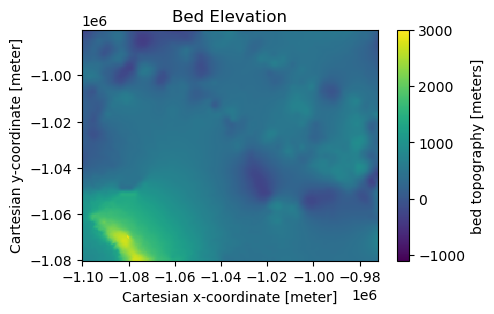

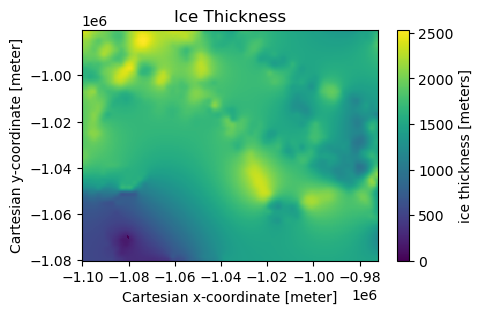

In [53]:
#initial Pots from Bedmachine3

#Plot bed elevation
fig, ax = plt.subplots(figsize=(5, 3))
test_area1["bed"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True, vmin = -1100, vmax = 3000)
ax.set_title("Bed Elevation")
ax.set_aspect("equal")
plt.show()

#Plot Ice Thickness
fig, ax = plt.subplots(figsize=(5, 3))
test_area1["thickness"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True)
ax.set_title("Ice Thickness")
ax.set_aspect("equal")
plt.show()

In [54]:
#adding radar data
xmin_ant = -3333250
xmax_ant = 3333250
ymin_ant = -3333250
ymax_ant = 3333250

resolution = 500
xx_ant, yy_ant = np.meshgrid(np.arange(xmin_ant, xmax_ant + resolution, resolution), 
                     np.arange(ymin_ant, ymax_ant + resolution, resolution))
xmin_ind = np.where(xx_ant == xmin)[1][0]
xmax_ind = np.where(xx_ant == xmax)[1][0]
ymin_ind = np.where(yy_ant == ymin)[0][0]
ymax_ind = np.where(yy_ant == ymax)[0][0]

In [55]:
# replace with the directory of your downloaded data

radar_thickness = np.load('Data/bedmap3_raw_thick_compilation.npy')
radar_thickness = np.flip(radar_thickness,axis=0)
radar_thickness = radar_thickness[ymin_ind:ymax_ind,xmin_ind:xmax_ind]

In [56]:
xx, yy = np.meshgrid(np.arange(xmin, xmax, resolution), 
                     np.arange(ymin, ymax, resolution))

(np.float64(-1100500.0),
 np.float64(-972500.0),
 np.float64(-1080500.0),
 np.float64(-980500.0))

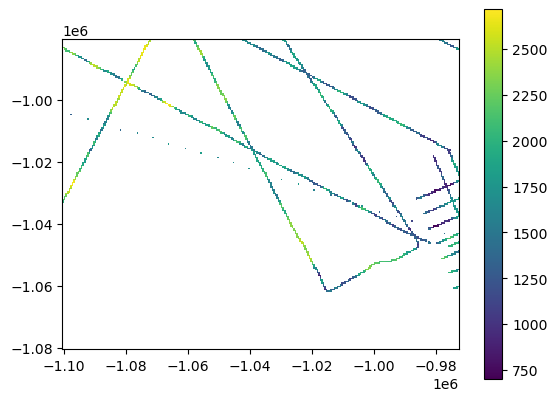

In [57]:
plt.pcolormesh(xx,yy,radar_thickness)
plt.colorbar()
plt.axis('scaled')

(np.float64(-1100500.0),
 np.float64(-972500.0),
 np.float64(-1080500.0),
 np.float64(-980500.0))

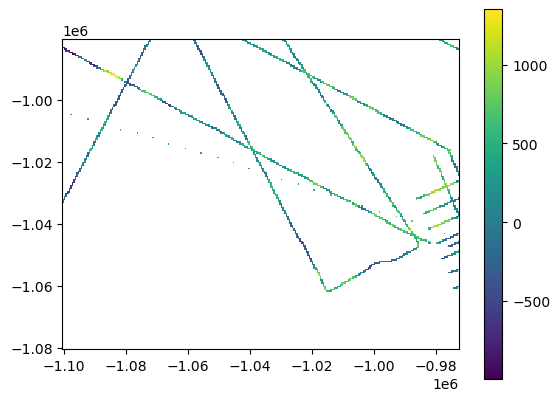

In [58]:
# bed elevation
plt.pcolormesh(xx,yy,test_area1['surface'].values.reshape(xx.shape) - radar_thickness)
plt.colorbar()
plt.axis('scaled')

(np.float64(-1100500.0),
 np.float64(-972500.0),
 np.float64(-1080500.0),
 np.float64(-980500.0))

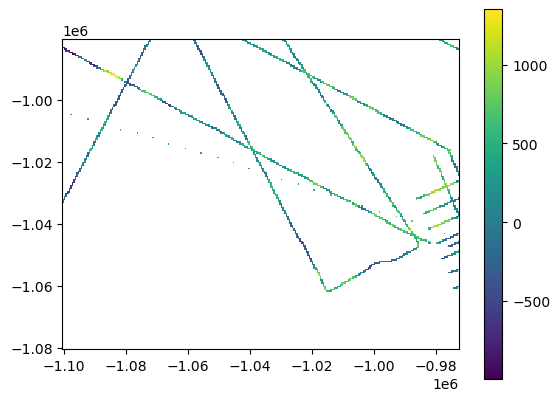

In [59]:
# bed elevation
plt.pcolormesh(xx,yy,test_area1['surface'].values.reshape(xx.shape) - radar_thickness)
plt.colorbar()
plt.axis('scaled')

In [60]:
# store radar data
test_area1['radar_bed'] = test_area1['surface'] - np.flipud(radar_thickness)

In [61]:
test_area1.head()


<xarray.Dataset> Size: 766B
Dimensions:    (y: 5, x: 5)
Coordinates:
  * y          (y) int32 20B -980500 -981000 -981500 -982000 -982500
  * x          (x) int32 20B -1100000 -1099500 -1099000 -1098500 -1098000
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 25B ...
    firn       (y, x) float32 100B ...
    surface    (y, x) float32 100B 2.14e+03 2.14e+03 ... 2.144e+03 2.145e+03
    thickness  (y, x) float32 100B ...
    bed        (y, x) float32 100B ...
    errbed     (y, x) float32 100B ...
    source     (y, x) int8 25B ...
    dataid     (y, x) int8 25B ...
    geoid      (y, x) int16 50B ...
    radar_bed  (y, x) float32 100B nan nan nan nan nan ... nan nan nan nan nan
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

In [62]:
#converting data to df
df = test_area1.to_dataframe().reset_index()
df.head()

,y,x,mapping,mask,firn,surface,thickness,bed,errbed,source,dataid,geoid,radar_bed
0,-980500,-1100000,b'',2,22.441532,2140.203613,2424.776123,-284.572510,34.0,5,0,-40,NaN
1,-980500,-1099500,b'',2,22.365541,2140.365234,2408.286621,-267.921387,36.0,5,0,-40,NaN
2,-980500,-1099000,b'',2,22.289549,2140.215576,2389.010254,-248.794678,38.0,5,0,-40,NaN
3,-980500,-1098500,b'',2,22.213558,2139.366455,2365.928467,-226.562012,41.0,5,0,-40,NaN
4,-980500,-1098000,b'',2,22.137568,2138.253906,2340.660889,-202.406982,45.0,5,0,-40,NaN


In [63]:
# grid data to 100 m resolution and remove coordinates with NaNs
res = 1000
df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(df, 'x', 'y', 'radar_bed', res)
df_grid = df_grid[df_grid["Z"].isnull() == False]
df_grid = df_grid.rename(columns = {"Z": "Bed"})


# normal score transformation
data = df_grid['Bed'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=500, output_distribution='normal').fit(data)
df_grid['Nbed'] = nst_trans.transform(data)


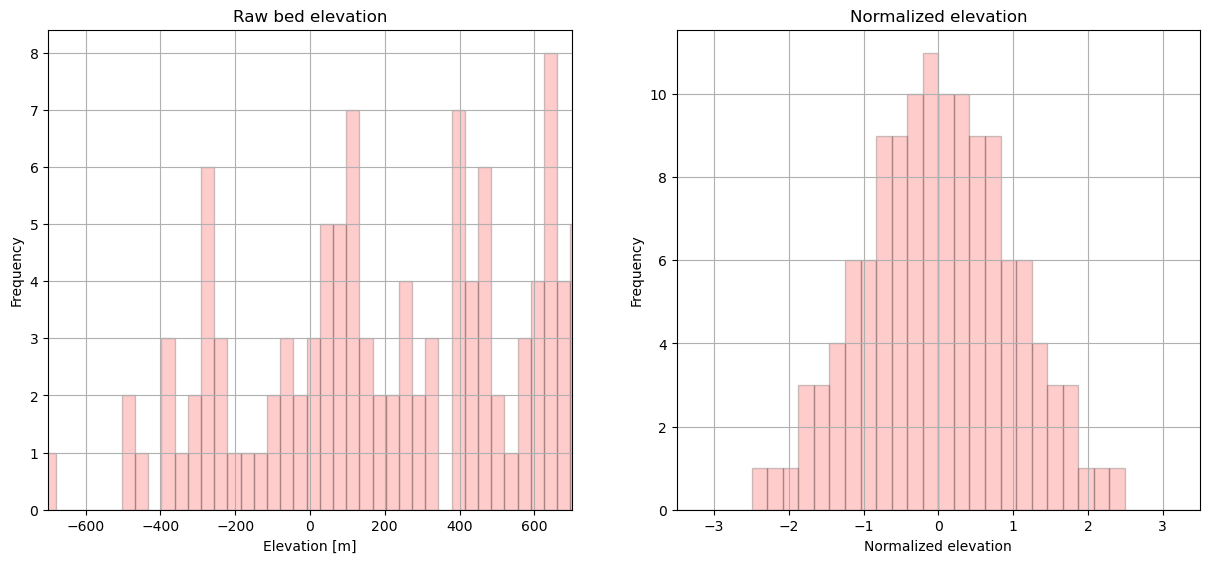

In [64]:
# plot original bed histogram
plt.subplot(121)
plt.hist(df_grid['Bed'], facecolor='red', bins=50, alpha=0.2, edgecolor='black')
plt.xlim([-700,700]); 
plt.xlabel('Elevation [m]'); plt.ylabel('Frequency'); plt.title('Raw bed elevation')
plt.grid(True)

# plot normal score bed histogram (with weights)
plt.subplot(122)
plt.hist(df_grid['Nbed'], facecolor='red', bins=50, alpha=0.2, edgecolor='black')
plt.xlim([-3.5,3.5]); 
plt.xlabel('Normalized elevation'); plt.ylabel('Frequency'); plt.title('Normalized elevation')
plt.grid(True)
plt.subplots_adjust(left=0.0, bottom=0.0, right=1.8, top=1.0, wspace=0.2, hspace=0.3)
plt.show()

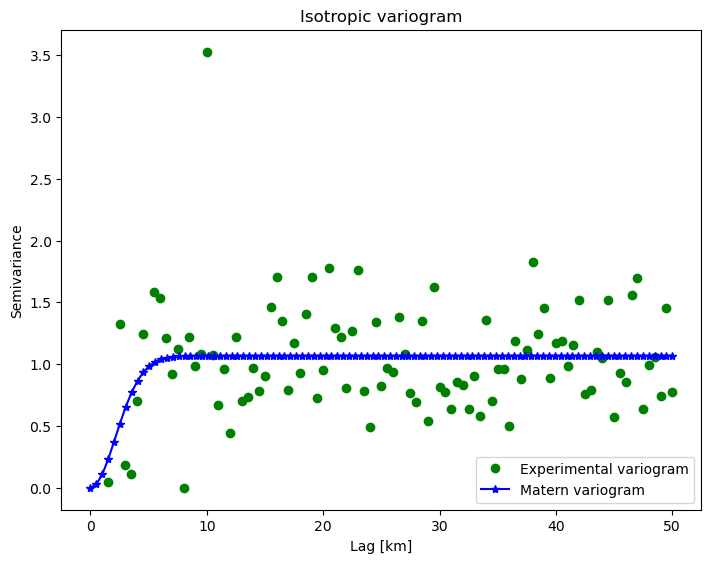

In [65]:
# compute experimental (isotropic) variogram
coords = df_grid[['X','Y']].values
values = df_grid['Nbed']

maxlag = 50000      # maximum range distance
n_lags = 100       # num of bins

# compute variogram
V1 = skg.Variogram(coords, values, bin_func='even', n_lags=n_lags, maxlag=maxlag, normalize=False)
# use exponential variogram model
V1.model = 'matern' 
V1.parameters

# extract variogram values
xdata = V1.bins
ydata = V1.experimental




xi =np.linspace(0, xdata[-1], 100) 
y_mat = [models.matern(h, V1.parameters[0], V1.parameters[1], V1.parameters[2]) for h in xi]

fig = plt.figure()
plt.plot(xdata/1000,ydata,'og', label = "Experimental variogram")
plt.plot(xi/1000, y_mat,'b*-', label='Matern variogram')
plt.title('Isotropic variogram')
plt.xlabel('Lag [km]'); plt.ylabel('Semivariance')  
plt.subplots_adjust(left=0.0, bottom=0.0, right=1, top=1.0) # adjust the plot size
plt.legend(loc='lower right')


In [50]:
# define coordinate grid
xmin = np.min(df_grid['X']); xmax = np.max(df_grid['X'])     # min and max x values
ymin = np.min(df_grid['Y']); ymax = np.max(df_grid['Y'])     # min and max y values

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)

In [51]:
azimuth = 0
nugget = V1.parameters[2]

# the major and minor ranges are the same in this example because it is isotropic
major_range = V1.parameters[0]
minor_range = V1.parameters[0]
sill = V1.parameters[1]
smoothness = 1
vtype = 'matern'

# save variogram parameters as a list
vario = [azimuth, nugget, major_range, minor_range, sill, vtype, smoothness]


k = 100       # number of neighboring data points used to estimate a given point
rad = 100000   # 50 km search radius

# est_SK is the estimate and var_SK is the variance
est_SK, var_SK = gs.Interpolation.skrige(Pred_grid_xy, df_grid, 'X', 'Y', 'Bed', k, vario, rad)

 30%|██▉       | 15543/51832 [02:41<06:17, 96.12it/s] 


KeyboardInterrupt: 